In [ ]:
%pip install -q pymongo dnspython

In [ ]:
from google.colab import userdata
from pymongo import MongoClient
uri = userdata.get("MONGODB_URI")
client = MongoClient(uri,serverSelectionTimeoutMS=20000)
client.admin.command("ping")
print("MongoDB Atlas connected successfully!")

MongoDB Atlas connected successfully!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,classification_report, accuracy_score
from sklearn.feature_selection import mutual_info_classif,SelectKBest

In [ ]:
df=pd.read_csv("/content/Dataset.csv")
df

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE,comment
0,synthetic_5877,119.844143,204.839768,NaN,0.0039215172344374,0.000032,0.001405,0.001725,0.004215,0.016158,...,0.004842,26.587659,0.0,0.523705,0.772247,-7.127907,0.162645,2.076849,0.102559,NaN
1,synthetic_6556,186.427970,216.031560,147.751368,0.0050355190203841,0.000026,0.002644,0.002666,0.007933,0.016012,...,0.008920,23.553221,0.0,NaN,0.702494,-7.029750,0.187427,2.223834,0.090310,NaN
2,synthetic_1449,110.612262,166.468222,74.167131,0.0138811235097507,0.000125,0.007959,0.006517,0.023878,0.044150,...,0.117388,15.422031,1.0,0.711838,0.668709,-5.240961,0.239259,2.275216,0.291261,NaN
3,synthetic_3352,119.097793,191.657743,110.135392,0.0056674990998936,0.000041,0.003307,0.003170,0.009920,0.032499,...,0.010070,21.157355,1.0,0.568098,0.785514,-5.485465,0.188179,2.329824,0.202871,NaN
4,synthetic_232,146.796232,215.743597,118.559333,0.0043241905988543,0.000033,0.001857,0.002500,0.005571,0.023467,...,0.008778,21.008180,1.0,0.601687,0.693088,-4.684917,0.370643,2.498216,0.250253,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,synthetic_6401,175.577189,221.237106,85.322791,0.0046807259107525,0.000028,0.002734,0.002327,0.008201,0.016877,...,0.005898,26.738197,1.0,0.354096,0.696125,-6.568326,0.138048,2.422829,0.130753,NaN
9996,synthetic_9161,171.943479,231.961164,95.991287,0.0051553563288228,0.000031,0.003146,0.003170,0.009437,0.038435,...,0.024779,19.260985,1.0,0.458830,0.751271,-6.928398,0.151614,2.684991,0.159062,NaN
9997,synthetic_9860,180.264939,205.862862,134.295242,0.0042842593318143,0.000023,0.001777,0.002050,0.005332,0.017519,...,0.007298,24.767060,1.0,NaN,0.706747,-5.985734,0.176399,2.090258,NaN,NaN
9998,synthetic_1689,139.620404,537.535279,104.970791,0.0109657622942607,0.000068,0.006378,0.007078,0.019135,0.027276,...,0.034821,19.611986,1.0,NaN,0.739091,-4.448410,0.275276,2.568696,0.275799,NaN


In [ ]:
df.head()

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE,comment
0,synthetic_5877,119.844143,204.839768,NaN,0.0039215172344374,0.000032,0.001405,0.001725,0.004215,0.016158,...,0.004842,26.587659,0.0,0.523705,0.772247,-7.127907,0.162645,2.076849,0.102559,NaN
1,synthetic_6556,186.427970,216.031560,147.751368,0.0050355190203841,0.000026,0.002644,0.002666,0.007933,0.016012,...,0.008920,23.553221,0.0,NaN,0.702494,-7.029750,0.187427,2.223834,0.090310,NaN
2,synthetic_1449,110.612262,166.468222,74.167131,0.0138811235097507,0.000125,0.007959,0.006517,0.023878,0.044150,...,0.117388,15.422031,1.0,0.711838,0.668709,-5.240961,0.239259,2.275216,0.291261,NaN
3,synthetic_3352,119.097793,191.657743,110.135392,0.0056674990998936,0.000041,0.003307,0.003170,0.009920,0.032499,...,0.010070,21.157355,1.0,0.568098,0.785514,-5.485465,0.188179,2.329824,0.202871,NaN
4,synthetic_232,146.796232,215.743597,118.559333,0.0043241905988543,0.000033,0.001857,0.002500,0.005571,0.023467,...,0.008778,21.008180,1.0,0.601687,0.693088,-4.684917,0.370643,2.498216,0.250253,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              10000 non-null  object 
 1   MDVP:Fo(Hz)       9702 non-null   float64
 2   MDVP:Fhi(Hz)      9700 non-null   float64
 3   MDVP:Flo(Hz)      9698 non-null   float64
 4   MDVP:Jitter(%)    9686 non-null   object 
 5   MDVP:Jitter(Abs)  10000 non-null  float64
 6   MDVP:RAP          10000 non-null  float64
 7   MDVP:PPQ          10000 non-null  float64
 8   Jitter:DDP        10000 non-null  float64
 9   MDVP:Shimmer      9703 non-null   float64
 10  MDVP:Shimmer(dB)  10000 non-null  float64
 11  Shimmer:APQ3      10000 non-null  float64
 12  Shimmer:APQ5      10000 non-null  float64
 13  MDVP:APQ          10000 non-null  float64
 14  Shimmer:DDA       10000 non-null  float64
 15  NHR               9701 non-null   float64
 16  HNR               9696 non-null   float64

In [ ]:
df.shape

(10000, 25)

In [ ]:
db = client["ParkinsonDB"]

patient_collection = db["patient_data"]
predictions_collection = db["prediction_results"]
metrics_collection = db["model_metrics"]

print("Database and collection references created!")

Database and collection references created!


In [ ]:
import json
patient_collection.delete_many({})
records = json.loads(df.to_json(orient="records", date_format="iso"))
if records:
    patient_collection.insert_many(records)
print("Records stored in MongoDB:",patient_collection.count_documents({}))
documents = list(patient_collection.find({}, {"_id": 0}))
df = pd.DataFrame(documents)
print("Dataset shape:", df.shape)
df.head()

Records stored in MongoDB: 10000
Dataset shape: (10000, 25)


,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE,comment
0,synthetic_5877,119.844143,204.839768,NaN,0.0039215172344374,0.000032,0.001405,0.001725,0.004215,0.016158,...,0.004842,26.587659,0.0,0.523705,0.772247,-7.127907,0.162645,2.076849,0.102559,None
1,synthetic_6556,186.427970,216.031560,147.751368,0.0050355190203841,0.000026,0.002644,0.002666,0.007933,0.016012,...,0.008920,23.553221,0.0,NaN,0.702494,-7.029750,0.187427,2.223834,0.090310,None
2,synthetic_1449,110.612262,166.468222,74.167131,0.0138811235097507,0.000125,0.007959,0.006517,0.023878,0.044150,...,0.117388,15.422031,1.0,0.711838,0.668709,-5.240961,0.239259,2.275216,0.291261,None
3,synthetic_3352,119.097793,191.657743,110.135392,0.0056674990998936,0.000041,0.003307,0.003170,0.009920,0.032499,...,0.010070,21.157355,1.0,0.568098,0.785514,-5.485465,0.188179,2.329824,0.202871,None
4,synthetic_232,146.796232,215.743597,118.559333,0.0043241905988543,0.000033,0.001857,0.002500,0.005571,0.023467,...,0.008778,21.008180,1.0,0.601687,0.693088,-4.684917,0.370643,2.498216,0.250253,None


In [ ]:
df.isnull().sum()

,0
name,0
MDVP:Fo(Hz),298
MDVP:Fhi(Hz),300
MDVP:Flo(Hz),302
MDVP:Jitter(%),314
MDVP:Jitter(Abs),0
MDVP:RAP,0
MDVP:PPQ,0
Jitter:DDP,0
MDVP:Shimmer,297


In [ ]:
print(df['status'].value_counts())

status
 1.0000    7360
 0.0000    2438
 2.0000      40
 1.0265       2
 1.0113       2
           ... 
-0.0203       1
 0.0387       1
 0.9420       1
 0.9655       1
 0.9693       1
Name: count, Length: 119, dtype: int64


In [ ]:
df=df.drop(columns=['comment','name'],errors="ignore")

In [ ]:
df.dropna()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
2,110.612262,166.468222,74.167131,0.0138811235097507,0.000125,0.007959,0.006517,0.023878,0.044150,0.450506,...,0.068992,0.117388,15.422031,1.0,0.711838,0.668709,-5.240961,0.239259,2.275216,0.291261
3,119.097793,191.657743,110.135392,0.0056674990998936,0.000041,0.003307,0.003170,0.009920,0.032499,0.299386,...,0.054409,0.010070,21.157355,1.0,0.568098,0.785514,-5.485465,0.188179,2.329824,0.202871
4,146.796232,215.743597,118.559333,0.0043241905988543,0.000033,0.001857,0.002500,0.005571,0.023467,0.233128,...,0.029677,0.008778,21.008180,1.0,0.601687,0.693088,-4.684917,0.370643,2.498216,0.250253
5,144.202930,185.638657,81.382534,0.0053946198997737,0.000036,0.002590,0.002364,0.007769,0.021178,0.199696,...,0.032658,0.055511,18.840409,1.0,0.540347,0.606299,-5.530593,0.207632,2.663326,0.194777
6,112.844389,149.342916,105.622888,0.0030063543611867,0.000023,0.001392,0.001679,0.004177,0.017219,0.158427,...,0.026281,0.004255,27.848509,0.0,0.275893,0.757081,-6.212493,0.141934,1.734664,0.144516
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9990,150.271988,265.407785,75.237945,0.0055416273693621,0.000034,0.002771,0.002700,0.008312,0.012562,0.124113,...,0.019205,0.014842,24.620812,1.0,0.543538,0.684237,-5.285927,0.279805,2.332433,0.207154
9991,152.392799,260.202104,146.626779,0.0086746820495295,0.000058,0.004318,0.005337,0.012954,0.033391,0.348150,...,0.049645,0.023079,18.213232,1.0,0.594124,0.721244,-4.122289,0.301319,2.614363,0.415333
9992,131.659294,195.378849,57.034937,0.0045154698554037,0.000033,0.001863,0.002556,0.005589,0.027016,0.248235,...,0.034959,0.008280,22.992556,1.0,0.592297,0.733854,-5.764743,0.315769,2.054196,0.241265
9995,175.577189,221.237106,85.322791,0.0046807259107525,0.000028,0.002734,0.002327,0.008201,0.016877,0.146954,...,0.024694,0.005898,26.738197,1.0,0.354096,0.696125,-6.568326,0.138048,2.422829,0.130753


In [ ]:

df.head()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,119.844143,204.839768,NaN,0.0039215172344374,0.000032,0.001405,0.001725,0.004215,0.016158,0.153035,...,0.024346,0.004842,26.587659,0.0,0.523705,0.772247,-7.127907,0.162645,2.076849,0.102559
1,186.427970,216.031560,147.751368,0.0050355190203841,0.000026,0.002644,0.002666,0.007933,0.016012,0.155172,...,0.025773,0.008920,23.553221,0.0,NaN,0.702494,-7.029750,0.187427,2.223834,0.090310
2,110.612262,166.468222,74.167131,0.0138811235097507,0.000125,0.007959,0.006517,0.023878,0.044150,0.450506,...,0.068992,0.117388,15.422031,1.0,0.711838,0.668709,-5.240961,0.239259,2.275216,0.291261
3,119.097793,191.657743,110.135392,0.0056674990998936,0.000041,0.003307,0.003170,0.009920,0.032499,0.299386,...,0.054409,0.010070,21.157355,1.0,0.568098,0.785514,-5.485465,0.188179,2.329824,0.202871
4,146.796232,215.743597,118.559333,0.0043241905988543,0.000033,0.001857,0.002500,0.005571,0.023467,0.233128,...,0.029677,0.008778,21.008180,1.0,0.601687,0.693088,-4.684917,0.370643,2.498216,0.250253


In [ ]:
df

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,119.844143,204.839768,NaN,0.0039215172344374,0.000032,0.001405,0.001725,0.004215,0.016158,0.153035,...,0.024346,0.004842,26.587659,0.0,0.523705,0.772247,-7.127907,0.162645,2.076849,0.102559
1,186.427970,216.031560,147.751368,0.0050355190203841,0.000026,0.002644,0.002666,0.007933,0.016012,0.155172,...,0.025773,0.008920,23.553221,0.0,NaN,0.702494,-7.029750,0.187427,2.223834,0.090310
2,110.612262,166.468222,74.167131,0.0138811235097507,0.000125,0.007959,0.006517,0.023878,0.044150,0.450506,...,0.068992,0.117388,15.422031,1.0,0.711838,0.668709,-5.240961,0.239259,2.275216,0.291261
3,119.097793,191.657743,110.135392,0.0056674990998936,0.000041,0.003307,0.003170,0.009920,0.032499,0.299386,...,0.054409,0.010070,21.157355,1.0,0.568098,0.785514,-5.485465,0.188179,2.329824,0.202871
4,146.796232,215.743597,118.559333,0.0043241905988543,0.000033,0.001857,0.002500,0.005571,0.023467,0.233128,...,0.029677,0.008778,21.008180,1.0,0.601687,0.693088,-4.684917,0.370643,2.498216,0.250253
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,175.577189,221.237106,85.322791,0.0046807259107525,0.000028,0.002734,0.002327,0.008201,0.016877,0.146954,...,0.024694,0.005898,26.738197,1.0,0.354096,0.696125,-6.568326,0.138048,2.422829,0.130753
9996,171.943479,231.961164,95.991287,0.0051553563288228,0.000031,0.003146,0.003170,0.009437,0.038435,0.364306,...,0.059862,0.024779,19.260985,1.0,0.458830,0.751271,-6.928398,0.151614,2.684991,0.159062
9997,180.264939,205.862862,134.295242,0.0042842593318143,0.000023,0.001777,0.002050,0.005332,0.017519,0.158094,...,0.027030,0.007298,24.767060,1.0,NaN,0.706747,-5.985734,0.176399,2.090258,NaN
9998,139.620404,537.535279,104.970791,0.0109657622942607,0.000068,0.006378,0.007078,0.019135,0.027276,0.305004,...,0.038053,0.034821,19.611986,1.0,NaN,0.739091,-4.448410,0.275276,2.568696,0.275799


In [ ]:
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [ ]:
df = df.replace([np.inf, -np.inf], np.nan)
df

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,119.844143,204.839768,NaN,0.003922,0.000032,0.001405,0.001725,0.004215,0.016158,0.153035,...,0.024346,0.004842,26.587659,0.0,0.523705,0.772247,-7.127907,0.162645,2.076849,0.102559
1,186.427970,216.031560,147.751368,0.005036,0.000026,0.002644,0.002666,0.007933,0.016012,0.155172,...,0.025773,0.008920,23.553221,0.0,NaN,0.702494,-7.029750,0.187427,2.223834,0.090310
2,110.612262,166.468222,74.167131,0.013881,0.000125,0.007959,0.006517,0.023878,0.044150,0.450506,...,0.068992,0.117388,15.422031,1.0,0.711838,0.668709,-5.240961,0.239259,2.275216,0.291261
3,119.097793,191.657743,110.135392,0.005667,0.000041,0.003307,0.003170,0.009920,0.032499,0.299386,...,0.054409,0.010070,21.157355,1.0,0.568098,0.785514,-5.485465,0.188179,2.329824,0.202871
4,146.796232,215.743597,118.559333,0.004324,0.000033,0.001857,0.002500,0.005571,0.023467,0.233128,...,0.029677,0.008778,21.008180,1.0,0.601687,0.693088,-4.684917,0.370643,2.498216,0.250253
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,175.577189,221.237106,85.322791,0.004681,0.000028,0.002734,0.002327,0.008201,0.016877,0.146954,...,0.024694,0.005898,26.738197,1.0,0.354096,0.696125,-6.568326,0.138048,2.422829,0.130753
9996,171.943479,231.961164,95.991287,0.005155,0.000031,0.003146,0.003170,0.009437,0.038435,0.364306,...,0.059862,0.024779,19.260985,1.0,0.458830,0.751271,-6.928398,0.151614,2.684991,0.159062
9997,180.264939,205.862862,134.295242,0.004284,0.000023,0.001777,0.002050,0.005332,0.017519,0.158094,...,0.027030,0.007298,24.767060,1.0,NaN,0.706747,-5.985734,0.176399,2.090258,NaN
9998,139.620404,537.535279,104.970791,0.010966,0.000068,0.006378,0.007078,0.019135,0.027276,0.305004,...,0.038053,0.034821,19.611986,1.0,NaN,0.739091,-4.448410,0.275276,2.568696,0.275799


In [ ]:
df = df.dropna(subset=["status"]).copy()
df

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,119.844143,204.839768,NaN,0.003922,0.000032,0.001405,0.001725,0.004215,0.016158,0.153035,...,0.024346,0.004842,26.587659,0.0,0.523705,0.772247,-7.127907,0.162645,2.076849,0.102559
1,186.427970,216.031560,147.751368,0.005036,0.000026,0.002644,0.002666,0.007933,0.016012,0.155172,...,0.025773,0.008920,23.553221,0.0,NaN,0.702494,-7.029750,0.187427,2.223834,0.090310
2,110.612262,166.468222,74.167131,0.013881,0.000125,0.007959,0.006517,0.023878,0.044150,0.450506,...,0.068992,0.117388,15.422031,1.0,0.711838,0.668709,-5.240961,0.239259,2.275216,0.291261
3,119.097793,191.657743,110.135392,0.005667,0.000041,0.003307,0.003170,0.009920,0.032499,0.299386,...,0.054409,0.010070,21.157355,1.0,0.568098,0.785514,-5.485465,0.188179,2.329824,0.202871
4,146.796232,215.743597,118.559333,0.004324,0.000033,0.001857,0.002500,0.005571,0.023467,0.233128,...,0.029677,0.008778,21.008180,1.0,0.601687,0.693088,-4.684917,0.370643,2.498216,0.250253
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,175.577189,221.237106,85.322791,0.004681,0.000028,0.002734,0.002327,0.008201,0.016877,0.146954,...,0.024694,0.005898,26.738197,1.0,0.354096,0.696125,-6.568326,0.138048,2.422829,0.130753
9996,171.943479,231.961164,95.991287,0.005155,0.000031,0.003146,0.003170,0.009437,0.038435,0.364306,...,0.059862,0.024779,19.260985,1.0,0.458830,0.751271,-6.928398,0.151614,2.684991,0.159062
9997,180.264939,205.862862,134.295242,0.004284,0.000023,0.001777,0.002050,0.005332,0.017519,0.158094,...,0.027030,0.007298,24.767060,1.0,NaN,0.706747,-5.985734,0.176399,2.090258,NaN
9998,139.620404,537.535279,104.970791,0.010966,0.000068,0.006378,0.007078,0.019135,0.027276,0.305004,...,0.038053,0.034821,19.611986,1.0,NaN,0.739091,-4.448410,0.275276,2.568696,0.275799


In [ ]:
print(df.isnull().sum())

MDVP:Fo(Hz)         298
MDVP:Fhi(Hz)        300
MDVP:Flo(Hz)        302
MDVP:Jitter(%)      358
MDVP:Jitter(Abs)      0
MDVP:RAP              0
MDVP:PPQ              0
Jitter:DDP            0
MDVP:Shimmer        296
MDVP:Shimmer(dB)      0
Shimmer:APQ3          0
Shimmer:APQ5          0
MDVP:APQ              0
Shimmer:DDA           0
NHR                 299
HNR                 301
status                0
RPDE                302
DFA                 301
spread1             301
spread2               0
D2                  297
PPE                 300
dtype: int64


In [ ]:
df["status"] = (df["status"] >= 0.5).astype(int)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9959 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MDVP:Fo(Hz)       9661 non-null   float64
 1   MDVP:Fhi(Hz)      9659 non-null   float64
 2   MDVP:Flo(Hz)      9657 non-null   float64
 3   MDVP:Jitter(%)    9601 non-null   float64
 4   MDVP:Jitter(Abs)  9959 non-null   float64
 5   MDVP:RAP          9959 non-null   float64
 6   MDVP:PPQ          9959 non-null   float64
 7   Jitter:DDP        9959 non-null   float64
 8   MDVP:Shimmer      9663 non-null   float64
 9   MDVP:Shimmer(dB)  9959 non-null   float64
 10  Shimmer:APQ3      9959 non-null   float64
 11  Shimmer:APQ5      9959 non-null   float64
 12  MDVP:APQ          9959 non-null   float64
 13  Shimmer:DDA       9959 non-null   float64
 14  NHR               9660 non-null   float64
 15  HNR               9658 non-null   float64
 16  status            9959 non-null   int64  
 17  

In [ ]:
print(df["status"].value_counts())

status
1    7495
0    2464
Name: count, dtype: int64


/tmp/ipykernel_512/3283823040.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='status', data=df, palette='Set2')


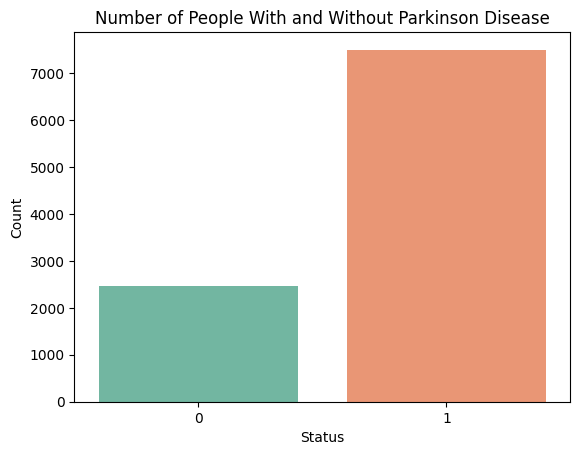

In [ ]:
sns.countplot(x='status', data=df, palette='Set2')
plt.title('Number of People With and Without Parkinson Disease')
plt.xlabel('Status')
plt.ylabel('Count')
plt.show()

In [ ]:
X = df.drop(columns=['status'])
Y = df['status']
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9959 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MDVP:Fo(Hz)       9661 non-null   float64
 1   MDVP:Fhi(Hz)      9659 non-null   float64
 2   MDVP:Flo(Hz)      9657 non-null   float64
 3   MDVP:Jitter(%)    9601 non-null   float64
 4   MDVP:Jitter(Abs)  9959 non-null   float64
 5   MDVP:RAP          9959 non-null   float64
 6   MDVP:PPQ          9959 non-null   float64
 7   Jitter:DDP        9959 non-null   float64
 8   MDVP:Shimmer      9663 non-null   float64
 9   MDVP:Shimmer(dB)  9959 non-null   float64
 10  Shimmer:APQ3      9959 non-null   float64
 11  Shimmer:APQ5      9959 non-null   float64
 12  MDVP:APQ          9959 non-null   float64
 13  Shimmer:DDA       9959 non-null   float64
 14  NHR               9660 non-null   float64
 15  HNR               9658 non-null   float64
 16  status            9959 non-null   int64  
 17  

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, stratify=Y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.impute import SimpleImputer
selection_imputer = SimpleImputer(strategy="median")
X_train_for_selection = selection_imputer.fit_transform(X_train)

In [ ]:
selection_scaler = StandardScaler()
X_train_for_selection = selection_scaler.fit_transform(X_train_for_selection)

In [ ]:
selector = SelectKBest(
    score_func=lambda features, labels: mutual_info_classif(
        features, labels, random_state=42
    ),
    k=min(10, X_train.shape[1])
)

selector.fit(X_train_for_selection, y_train)

selected_features = X_train.columns[
    selector.get_support()
].tolist()

print("Selected Features:")
for i, feature in enumerate(selected_features, start=1):
    print(feature)

Selected Features:
MDVP:Jitter(Abs)
MDVP:Shimmer
MDVP:Shimmer(dB)
Shimmer:APQ3
Shimmer:APQ5
MDVP:APQ
Shimmer:DDA
spread1
spread2
PPE


In [ ]:
feature_selection_results = pd.DataFrame({
    "Feature": X_train.columns,
    "Mutual Information Score": selector.scores_,
    "Selected": selector.get_support()
}).sort_values(
    "Mutual Information Score",
    ascending=False
)
feature_selection_results.to_csv(
    "feature_selection_results.csv",
    index=False
)
display(feature_selection_results)

,Feature,Mutual Information Score,Selected
21,PPE,0.217821,True
18,spread1,0.210932,True
12,MDVP:APQ,0.170306,True
19,spread2,0.162982,True
11,Shimmer:APQ5,0.141822,True
8,MDVP:Shimmer,0.132275,True
9,MDVP:Shimmer(dB),0.128568,True
4,MDVP:Jitter(Abs),0.118879,True
13,Shimmer:DDA,0.106030,True
10,Shimmer:APQ3,0.106030,True


In [ ]:
X_train_10 = X_train[selected_features].copy()
X_test_10 = X_test[selected_features].copy()

In [ ]:
imputer = SimpleImputer(strategy="median")
X_train_10_imputed = imputer.fit_transform(X_train_10)
X_test_10_imputed = imputer.transform(X_test_10)

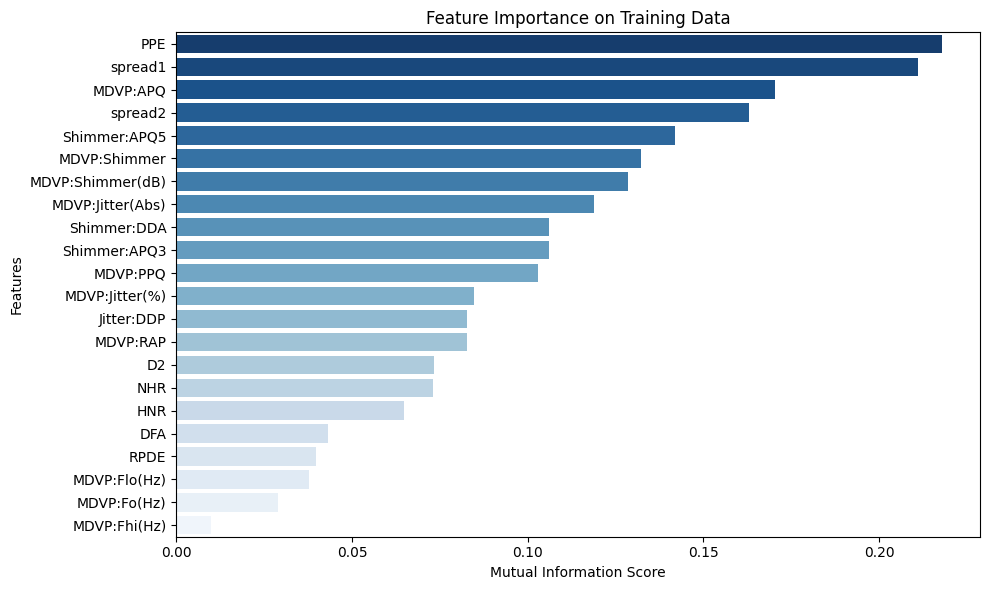

In [ ]:
mi_scores = pd.Series(
    selector.scores_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=mi_scores.values,
    y=mi_scores.index,
    hue=mi_scores.index,
    palette="Blues_r",
    legend=False
)

plt.xlabel("Mutual Information Score")
plt.ylabel("Features")
plt.title("Feature Importance on Training Data")
plt.tight_layout()
plt.show()

In [ ]:
scaler = StandardScaler()
X_train_10_scaled = scaler.fit_transform(
    X_train_10_imputed
)

X_test_10_scaled = scaler.transform(
    X_test_10_imputed
)
print("Final training shape:", X_train_10_scaled.shape)
print("Final testing shape:", X_test_10_scaled.shape)


Final training shape: (7967, 10)
Final testing shape: (1992, 10)


In [ ]:
svm_default = SVC()
svm_default.fit(X_train_10_scaled, y_train)
y_pred_default = svm_default.predict(X_test_10_scaled)
accuracy_default = accuracy_score(y_test, y_pred_default)
print(
    f"Default SVM Test Accuracy: "
    f"{accuracy_default * 100:.2f}%"
)
print(classification_report(
    y_test,
    y_pred_default,
    target_names=["Non-Parkinson", "Parkinson"],
    zero_division=0
))

Default SVM Test Accuracy: 89.41%
               precision    recall  f1-score   support

Non-Parkinson       0.78      0.80      0.79       493
    Parkinson       0.93      0.92      0.93      1499

     accuracy                           0.89      1992
    macro avg       0.86      0.86      0.86      1992
 weighted avg       0.90      0.89      0.89      1992



In [ ]:
param_grid = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}
grid_svm = GridSearchCV(SVC(), param_grid, cv=5,scoring='accuracy')
grid_svm.fit(X_train_10_scaled, y_train)

best_svm = grid_svm.best_estimator_
print("Best Parameters:", grid_svm.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_svm.best_score_ * 100:.2f}%")

Best Parameters: {'C': 10, 'kernel': 'rbf'}
Best Cross-Validation Accuracy: 91.88%


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Default SVM": SVC(),
    "Tuned SVM": best_svm,
}

model_results = []

for name, model in models.items():
    model.fit(X_train_10_scaled, y_train)

    preds = model.predict(X_test_10_scaled)

    acc = accuracy_score(y_test, preds)
    precision = precision_score(
        y_test, preds, zero_division=0
    )
    recall = recall_score(
        y_test, preds, zero_division=0
    )
    f1 = f1_score(
        y_test, preds, zero_division=0
    )

    model_results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })
    print(f"\n===== {name} =====")
    print(f"Accuracy: {acc * 100:.2f}%")
    print(classification_report(
        y_test,
        preds,
        target_names=["Non-Parkinson", "Parkinson"],
        zero_division=0
    ))



===== Logistic Regression =====
Accuracy: 84.79%
               precision    recall  f1-score   support

Non-Parkinson       0.71      0.66      0.68       493
    Parkinson       0.89      0.91      0.90      1499

     accuracy                           0.85      1992
    macro avg       0.80      0.78      0.79      1992
 weighted avg       0.84      0.85      0.85      1992


===== Default SVM =====
Accuracy: 89.41%
               precision    recall  f1-score   support

Non-Parkinson       0.78      0.80      0.79       493
    Parkinson       0.93      0.92      0.93      1499

     accuracy                           0.89      1992
    macro avg       0.86      0.86      0.86      1992
 weighted avg       0.90      0.89      0.89      1992


===== Tuned SVM =====
Accuracy: 91.67%
               precision    recall  f1-score   support

Non-Parkinson       0.83      0.84      0.83       493
    Parkinson       0.95      0.94      0.94      1499

     accuracy                      

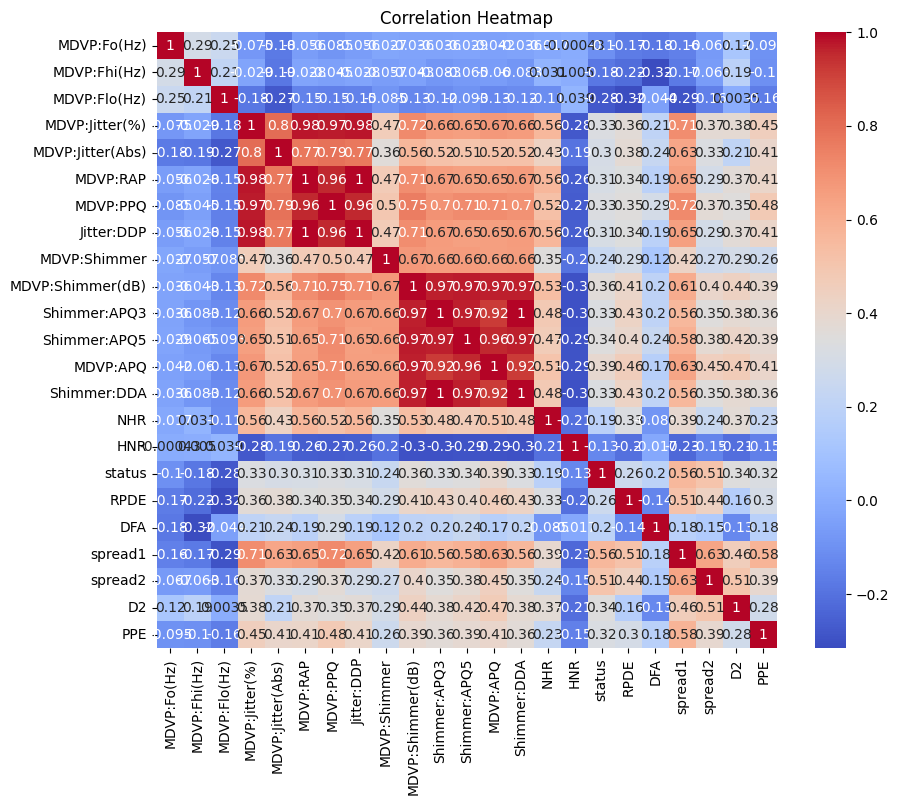

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
y_pred = best_svm.predict(X_test_10_scaled)

print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Parkinson", "Parkinson"],
    zero_division=0
))

               precision    recall  f1-score   support

Non-Parkinson       0.83      0.84      0.83       493
    Parkinson       0.95      0.94      0.94      1499

     accuracy                           0.92      1992
    macro avg       0.89      0.89      0.89      1992
 weighted avg       0.92      0.92      0.92      1992



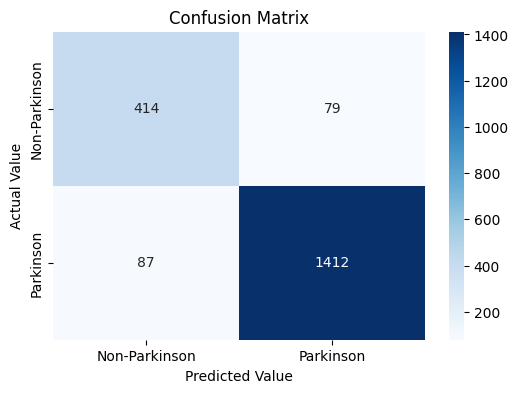

In [ ]:
a = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    a,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Parkinson", "Parkinson"],
    yticklabels=["Non-Parkinson", "Parkinson"]
)

plt.xlabel("Predicted Value")
plt.ylabel("Actual Value")
plt.title("Confusion Matrix")
plt.show()

Store the metrices in atlas

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
evaluation = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(
        precision_score(y_test, y_pred, zero_division=0)
    ),
    "recall": float(
        recall_score(y_test, y_pred, zero_division=0)
    ),
    "f1_score": float(
        f1_score(y_test, y_pred, zero_division=0)
    )
}

print("Evaluation Results")
for metric, value in evaluation.items():
    print(f"{metric}: {value:.4f}")

Evaluation Results
accuracy: 0.9167
precision: 0.9470
recall: 0.9420
f1_score: 0.9445


In [ ]:
# metrics_collection.delete_many({})
# predictions_collection.delete_many({})

In [ ]:
from datetime import datetime, timezone
evaluation["created_at"] = datetime.now(timezone.utc)
metrics_collection.insert_one(evaluation)
print("Evaluation metrics saved to Atlas")

Evaluation metrics saved to Atlas


In [ ]:
prediction_records = [
    {
        "model": "SVM",
        "actual_status": int(actual),
        "predicted_status": int(predicted),
        "created_at": datetime.now(timezone.utc)
    }
    for actual, predicted in zip(y_test.to_numpy(), y_pred)
]

if prediction_records:
    predictions_collection.insert_many(prediction_records)

print("Predictions saved:", len(prediction_records))

Predictions saved: 1992


In [ ]:
joblib.dump(imputer, "imputer.joblib")
joblib.dump(scaler, "scaler.joblib")
joblib.dump(best_svm, "model.joblib")
joblib.dump(selected_features, "feature_columns.joblib")
feature_selection_results.to_csv(
    "feature_selection_results.csv",
    index=False
)

In [ ]:
import sys
import sklearn
import numpy
import pandas
import scipy
import joblib

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("SciPy:", scipy.__version__)
print("Joblib:", joblib.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
scikit-learn: 1.6.1
NumPy: 2.4.6
Pandas: 2.2.3
SciPy: 1.16.3
Joblib: 1.6.0
